# Matplotlib Advanced

## Quick notes

### What this covers
Multi-panel layouts, twin and inset axes, annotation, colormaps and norms, colorbars, image/mesh/contour plots, 2D histograms, vector fields, 3D axes, tick locators and formatters, dates, log/symlog scales, patches, a minimal FuncAnimation, and event notes.

### Key points
- `plt.subplots(r, c)` returns an array of Axes; use `axs.flat` to loop; `squeeze=False` always gives 2D.
- `sharex` / `sharey` link limits and hide inner labels. Use `layout="constrained"` to stop overlaps (`tight_layout` is the older tool).
- `GridSpec` and `plt.subplot_mosaic("AAB;CDB")` build irregular grids.
- `ax.twinx()` adds a second y-scale; `ax.inset_axes([x, y, w, h])` adds a small plot inside.
- `ax.annotate(text, xy, xytext, arrowprops=...)` points at data; `textcoords="offset points"` keeps the offset fixed.
- A colormap maps 0-1 to colours; a **Norm** maps your data to 0-1. `LogNorm` for wide ranges, `TwoSlopeNorm(vcenter=0)` for diverging data.
- `fig.colorbar(mappable, ax=ax, label=...)`. `imshow` shows an array as an image (row 0 on top); `pcolormesh` handles uneven grids.
- `contour` = lines, `contourf` = filled; `hist2d` / `hexbin` for dense scatter; `quiver` / `streamplot` for vector fields.
- 3D: `fig.add_subplot(projection="3d")`, `plot_surface`, `view_init`.
- Locators choose tick positions, Formatters choose tick text. Dates go straight in; use `mdates` for format.
- `set_yscale("log")` needs positive data; `"symlog"` copes with zero/negatives.
- Patches need `ax.add_patch(...)` and manual limits; `set_aspect("equal")` keeps circles round.
- `FuncAnimation` needs a kept reference; saving needs ffmpeg/pillow (not done here).

### Gotchas (the part worth revising twice)
- Drop the reference to a `FuncAnimation` and nothing runs (or a "deleted without rendering" warning appears).
- `LogNorm` on negative values yields masked output, not an error; log axes silently hide non-positive points.
- `imshow` has the origin at the top-left; `origin="lower"` or `extent=` changes that.
- `pcolormesh` with `shading="flat"` needs C one smaller than X/Y.
- Adding patches does not autoscale the axes.
- Event callbacks and widgets do nothing under Agg; keep widget objects referenced.
- Do not mix `constrained` layout and `tight_layout`.

### When it matters
Dashboards, scientific figures, heatmaps, time series with ticks, and any figure needing more than one simple panel.

### One-line recap example
```python
import matplotlib.pyplot as plt, numpy as np
fig, axs = plt.subplots(1, 2, sharey=True, layout="constrained")
im = axs[0].imshow(np.random.rand(5, 5)); fig.colorbar(im, ax=axs[0], label="value")
```

In [1]:
# 01. Subplot Grids, sharex and sharey
# 02. Layout: constrained_layout vs tight_layout
# 03. GridSpec and subplot_mosaic
# 04. Twin Axes (Two y Scales)
# 05. Inset Axes
# 06. Text, Annotate and Arrows
# 07. Colormaps and Norms
# 08. Colorbars
# 09. imshow vs pcolormesh
# 10. contour and contourf
# 11. hist2d and hexbin
# 12. quiver and streamplot
# 13. 3D Axes
# 14. Custom Ticks: Locators and Formatters
# 15. Dates on Axes
# 16. Log and Symlog Scales
# 17. Patches and Shapes
# 18. FuncAnimation Basics (No Files)
# 19. Events and Interactivity (Notes)

import os
os.environ.setdefault("MPLBACKEND", "Agg")   # headless; in Jupyter the inline backend is already set

import io
import datetime as dt
import warnings

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import matplotlib.patches as mpatches

# plt.show() under Agg only warns "cannot be shown"; silence just that message
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

rng = np.random.default_rng(0)
x = np.linspace(0, 10, 200)

## 01. Subplot Grids, sharex and sharey

- fig, axs = plt.subplots(nrows, ncols) returns a NumPy array of Axes
  (2D if both > 1; 1D if one of them is 1; a single Axes if 1x1).
- axs.flat (or axs.ravel()) loops over every Axes in one go.
- squeeze=False ALWAYS gives a 2D array - safer in reusable code.
- sharex=True / sharey=True link the axes: same limits, and inner tick
  labels are hidden so the grid looks clean.
- sharex="col" / sharey="row" share per column / per row only.

In [2]:
fig, axs = plt.subplots(2, 3, sharex=True, sharey="row")
print("axs type/shape:", type(axs).__name__, axs.shape)
for i, ax in enumerate(axs.flat):
    ax.plot(x, np.sin(x + i))
axs[0, 0].set_xlim(0, 5)
print("shared xlim propagated:", all(a.get_xlim() == (0.0, 5.0) for a in axs.flat))
print("y labels shown by column:", [axs[0, c].yaxis.get_tick_params()["labelleft"] for c in range(3)])
print("single row ->", type(plt.subplots(1, 3)[1]).__name__, "| squeeze=False ->",
      plt.subplots(1, 3, squeeze=False)[1].shape)
plt.close("all")

axs type/shape: ndarray (2, 3)
shared xlim propagated: True
y labels shown by column: [True, False, False]
single row -> ndarray | squeeze=False -> (1, 3)


## 02. Layout: constrained_layout vs tight_layout

- Problem: titles, labels and colorbars overlap in multi-plot figures.
- layout="constrained" (fig, axs = plt.subplots(..., layout="constrained"))
  is the modern solution: it also handles colorbars and suptitle.
- fig.tight_layout() is the older one-shot adjustment; call it AFTER all
  plotting. Do not mix the two.
- Manual: fig.subplots_adjust(wspace=..., hspace=...).

In [3]:
fig, axs = plt.subplots(2, 2, layout="constrained")
for ax in axs.flat:
    ax.set_title("a title")
    ax.set_xlabel("x label")
fig.suptitle("overall")
fig.canvas.draw()
print("layout engine:", type(fig.get_layout_engine()).__name__)
fig2, ax2 = plt.subplots()
print("default layout engine:", fig2.get_layout_engine())
plt.close("all")

layout engine: ConstrainedLayoutEngine
default layout engine: None


## 03. GridSpec and subplot_mosaic

- GridSpec lets one plot span several cells: gs[0, :] is the whole top row.
- plt.subplot_mosaic("AAB;CDB") draws the layout as text: same letter =
  one merged Axes. It returns (fig, dict_of_axes) - much more readable.
- width_ratios / height_ratios change relative sizes.

In [4]:
fig = plt.figure(layout="constrained")
gs = fig.add_gridspec(2, 3, width_ratios=[2, 1, 1])
top = fig.add_subplot(gs[0, :])           # spans all 3 columns
bl = fig.add_subplot(gs[1, 0])
br = fig.add_subplot(gs[1, 1:])           # spans last 2 columns
print("gridspec axes:", len(fig.axes), "| top spans cols:", top.get_subplotspec().colspan)
plt.close(fig)

fig, ax_dict = plt.subplot_mosaic("AAB;CDB", layout="constrained")
print("mosaic keys:", sorted(ax_dict), "| B spans rows:", ax_dict["B"].get_subplotspec().rowspan)
plt.close(fig)

gridspec axes: 3 | top spans cols: range(0, 3)
mosaic keys: ['A', 'B', 'C', 'D'] | B spans rows: range(0, 2)


## 04. Twin Axes (Two y Scales)

- ax2 = ax.twinx() shares the x-axis and adds a second y-axis on the right
  (twiny for the top). Handy for different units (e.g. temp and rainfall).
- The twin is a NEW Axes: legends must be combined by hand and colour the
  label to match its line.
- Warning (see file 04): dual axes can be misleading, scale choice is
  arbitrary and can fake a correlation.

In [5]:
fig, ax = plt.subplots()
(l1,) = ax.plot(x, np.sin(x), color="C0", label="sin")
ax2 = ax.twinx()
(l2,) = ax2.plot(x, 100 * np.cos(x), color="C1", label="100*cos")
ax.set_ylabel("sin", color="C0")
ax2.set_ylabel("cos x100", color="C1")
ax.legend(handles=[l1, l2], loc="upper right")
print("axes in figure:", len(fig.axes), "| y limits differ:", ax.get_ylim() != ax2.get_ylim())
print("x shared:", ax.get_shared_x_axes().joined(ax, ax2))
print("legend entries:", [t.get_text() for t in ax.get_legend().get_texts()])
plt.close(fig)

axes in figure: 2 | y limits differ: True
x shared: True
legend entries: ['sin', '100*cos']


## 05. Inset Axes

- ax.inset_axes([x0, y0, width, height]) makes a small Axes inside, using
  axes-fraction coordinates (0-1) by default.
- ax.indicate_inset_zoom(inset) draws the box and connector lines to show
  which region is magnified.

In [6]:
fig, ax = plt.subplots()
ax.plot(x, np.sin(x))
inset = ax.inset_axes([0.55, 0.55, 0.4, 0.35])
inset.plot(x, np.sin(x))
inset.set_xlim(2, 4)
inset.set_ylim(-1, 0.2)
ax.indicate_inset_zoom(inset)
print("inset is an Axes:", isinstance(inset, matplotlib.axes.Axes), "| child axes of ax:", len(ax.child_axes))
print("inset xlim:", inset.get_xlim())
plt.close(fig)

inset is an Axes: True | child axes of ax: 1
inset xlim: (2.0, 4.0)


## 06. Text, Annotate and Arrows

- ax.text(x, y, "s") places text in DATA coordinates; transform=ax.transAxes
  switches to axes fractions (0-1) - good for corner labels.
- ax.annotate("text", xy=point, xytext=label_pos, arrowprops=dict(...))
  draws text plus an arrow pointing at xy.
- textcoords="offset points" keeps the label a fixed distance away even if
  you zoom or resize.
- ax.axhline / axvline / axvspan draw reference lines and bands.

In [7]:
fig, ax = plt.subplots()
ax.plot(x, np.sin(x))
peak_x = x[np.argmax(np.sin(x))]
ann = ax.annotate("peak", xy=(peak_x, 1), xytext=(20, -30), textcoords="offset points",
                  arrowprops=dict(arrowstyle="->"))
ax.text(0.02, 0.95, "corner", transform=ax.transAxes)
ax.axhline(0, color="grey", lw=0.8)
ax.axvspan(2, 3, alpha=0.2)
print("annotation text:", ann.get_text(), "| xy:", tuple(round(float(v), 2) for v in ann.xy))
print("has arrow:", ann.arrow_patch is not None)
print("texts:", [t.get_text() for t in ax.texts])
print("peak near pi/2:", bool(abs(peak_x - np.pi / 2) < 0.06))
plt.close(fig)

annotation text: peak | xy: (1.56, 1.0)
has arrow: True
texts: ['peak', 'corner']
peak near pi/2: True


## 07. Colormaps and Norms

- A colormap maps numbers 0-1 to colours; a Norm maps your data range to 0-1.
- Sequential: "viridis" (default, perceptually uniform), "magma", "Blues".
  Diverging: "RdBu", "coolwarm". Qualitative: "tab10". Avoid "jet"/"rainbow".
- Reverse any map by adding "_r" (viridis_r).
- Normalize(vmin, vmax): linear. LogNorm: for data spanning orders of
  magnitude (must be > 0). TwoSlopeNorm(vcenter=0): centre a diverging map
  on a meaningful value.
- plt.get_cmap / matplotlib.colormaps["name"] retrieve a map.

In [8]:
cmap = matplotlib.colormaps["viridis"]
print("cmap name:", cmap.name, "| N colors:", cmap.N)
print("viridis(0) hex:", mcolors.to_hex(cmap(0.0)), "| viridis(1) hex:", mcolors.to_hex(cmap(1.0)))
print("reversed name:", cmap.reversed().name)
lin = mcolors.Normalize(vmin=0, vmax=100)
log = mcolors.LogNorm(vmin=1, vmax=1000)
two = mcolors.TwoSlopeNorm(vmin=-2, vcenter=0, vmax=10)
print("Normalize(50):", float(lin(50)))
print("LogNorm(10):", round(float(log(10)), 3), "(1 of 3 decades)")
print("TwoSlopeNorm: -2 ->", float(two(-2)), "| 0 ->", float(two(0)), "| 10 ->", float(two(10)))
print("LogNorm(-5) is masked, not an error:", bool(np.ma.is_masked(log(-5))))

cmap name: viridis | N colors: 256
viridis(0) hex: #440154 | viridis(1) hex: #fde725
reversed name: viridis_r
Normalize(50): 0.5
LogNorm(10): 0.333 (1 of 3 decades)
TwoSlopeNorm: -2 -> 0.0 | 0 -> 0.5 | 10 -> 1.0
LogNorm(-5) is masked, not an error: True


## 08. Colorbars

- fig.colorbar(mappable, ax=ax) adds a legend for colour. The mappable is
  the object returned by imshow/scatter/pcolormesh/contourf.
- Pass ax= (or ax=list_of_axes) so space is stolen from the right axes;
  without ax= matplotlib has to guess (and fails if there is no parent).
- cbar.set_label("units") - always label what the colour means.
- The colorbar is its own Axes (cbar.ax).

In [9]:
data = rng.random((6, 8))
fig, ax = plt.subplots(layout="constrained")
im = ax.imshow(data, cmap="magma", vmin=0, vmax=1)
cbar = fig.colorbar(im, ax=ax, label="value")
print("axes now:", len(fig.axes), "| cbar label:", cbar.ax.get_ylabel())
print("cbar limits:", cbar.ax.get_ylim())
plt.close(fig)

axes now: 2 | cbar label: value
cbar limits: (0.0, 1.0)


## 09. imshow vs pcolormesh

- imshow(array): treats the array as an IMAGE: pixel (row, col), row 0 at
  the TOP by default. Fast; best for evenly spaced grids and real images.
  origin="lower" puts row 0 at the bottom; extent=(l, r, b, t) sets
  data coordinates.
- pcolormesh(X, Y, C): a mesh with explicit cell edges - works with
  UNEVEN spacing and curved grids. Rows go up with Y (no flipping).
- Gotcha: with shading="flat", C must be one smaller than X/Y in each
  dimension; use shading="auto" (default) to avoid the mismatch error.

In [10]:
arr = np.arange(12).reshape(3, 4)
fig, (a1, a2) = plt.subplots(1, 2)
img = a1.imshow(arr)
print("imshow array shape:", img.get_array().shape, "| ylim (row 0 on top):", a1.get_ylim())
a1b = plt.subplots()[1]
img2 = a1b.imshow(arr, origin="lower", extent=(0, 4, 0, 3))
print("origin=lower ylim:", a1b.get_ylim(), "| extent:", img2.get_extent())
X, Y = np.meshgrid([0, 1, 4, 9], [0, 2, 3])        # uneven spacing
mesh = a2.pcolormesh(X, Y, arr[:2, :3])           # flat shading needs C smaller
print("pcolormesh type:", type(mesh).__name__, "| xlim:", a2.get_xlim())
plt.close("all")

imshow array shape: (3, 4) | ylim (row 0 on top): (2.5, -0.5)
origin=lower ylim: (0.0, 3.0) | extent: [0, 4, 0, 3]
pcolormesh type: QuadMesh | xlim: (0.0, 9.0)


## 10. contour and contourf

- contour draws lines of equal value; contourf fills between levels.
- Inputs: X, Y 2D grids (np.meshgrid) and Z of the same shape.
- levels=int (approx count) or a list of exact levels.
- clabel(cs) writes the value on the lines.
- The returned object has .levels (the chosen level values).

In [11]:
gx, gy = np.meshgrid(np.linspace(-2, 2, 40), np.linspace(-2, 2, 40))
z = np.exp(-(gx ** 2 + gy ** 2))
fig, (a1, a2) = plt.subplots(1, 2, layout="constrained")
cs = a1.contour(gx, gy, z, levels=[0.1, 0.5, 0.9])
a1.clabel(cs)
csf = a2.contourf(gx, gy, z, levels=5, cmap="Blues")
fig.colorbar(csf, ax=a2)
print("line levels:", cs.levels.tolist())
print("filled levels count:", len(csf.levels), "| min/max:", float(csf.levels.min()), float(csf.levels.max()))
print("contour labels drawn:", len(a1.texts) >= 3 or len(cs.labelTexts) > 0)
plt.close(fig)

line levels:

 [0.1, 0.5, 0.9]
filled levels count: 6 | min/max: 0.0 1.0
contour labels drawn: True


## 11. hist2d and hexbin

- Two-variable histograms for lots of points where scatter becomes a blob.
- ax.hist2d(x, y, bins) -> square bins; returns (counts, xedges, yedges, image).
- ax.hexbin(x, y, gridsize) -> hexagonal bins; looks smoother.
- Add a colorbar labelled "count".

In [12]:
px = rng.normal(size=5000)
py = px * 0.6 + rng.normal(size=5000) * 0.8
fig, (a1, a2) = plt.subplots(1, 2, layout="constrained")
counts, xe, ye, im = a1.hist2d(px, py, bins=20)
hb = a2.hexbin(px, py, gridsize=15)
fig.colorbar(hb, ax=a2, label="count")
print("hist2d shape:", counts.shape, "| total counts == n:", int(counts.sum()) == 5000)
print("hexbin total:", int(hb.get_array().sum()))
plt.close(fig)

hist2d shape: (20, 20) | total counts == n: True
hexbin total: 5000


## 12. quiver and streamplot

- Vector fields: each point has a direction (u, v).
- ax.quiver(X, Y, U, V) draws arrows (returns a Quiver collection).
  Thin out the grid ([::3]) or arrows overlap.
- ax.streamplot(X, Y, U, V) draws flow lines; X, Y must be evenly spaced.
  Returns StreamplotSet with .lines and .arrows.

In [13]:
qx, qy = np.meshgrid(np.linspace(-1, 1, 8), np.linspace(-1, 1, 8))
u, v = -qy, qx                       # a rotation field
fig, (a1, a2) = plt.subplots(1, 2)
q = a1.quiver(qx, qy, u, v)
sx, sy = np.meshgrid(np.linspace(-1, 1, 20), np.linspace(-1, 1, 20))
sp = a2.streamplot(sx, sy, -sy, sx, density=0.8)
print("quiver arrows:", len(q.U), "| streamplot has lines:", len(sp.lines.get_paths()) > 0)
plt.close(fig)

quiver arrows: 64 | streamplot has lines: True


## 13. 3D Axes

- fig.add_subplot(projection="3d") (no extra import needed in modern
  matplotlib) gives an Axes3D with z-axis methods.
- plot_surface(X, Y, Z), plot_wireframe, scatter(x, y, z), plot(x, y, z),
  set_zlabel, view_init(elev, azim) to rotate.
- 3D is hard to read precisely and static images hide parts; prefer
  heatmap/contour unless the 3D shape is the message.

In [14]:
X, Y = np.meshgrid(np.linspace(-2, 2, 30), np.linspace(-2, 2, 30))
Z = np.sin(X ** 2 + Y ** 2)
fig = plt.figure()
ax3 = fig.add_subplot(projection="3d")
surf = ax3.plot_surface(X, Y, Z, cmap="viridis")
ax3.scatter(rng.random(5), rng.random(5), rng.random(5))
ax3.set_zlabel("z")
ax3.view_init(elev=30, azim=45)
print("axes class:", type(ax3).__name__, "| surface type:", type(surf).__name__)
print("view elev/azim:", ax3.elev, ax3.azim)
print("zlim ok:", ax3.get_zlim()[0] < ax3.get_zlim()[1], "| zlabel:", ax3.get_zlabel())
plt.close(fig)

axes class: Axes3D | surface type: Poly3DCollection
view elev/azim: 30 45
zlim ok: True | zlabel: z


## 14. Custom Ticks: Locators and Formatters

- Locator decides WHERE ticks go; Formatter decides HOW they are written.
- MultipleLocator(5), MaxNLocator(nbins=4), FixedLocator([...]),
  LogLocator for log axes.
- Formatters: FuncFormatter(lambda v, pos: ...), PercentFormatter,
  StrMethodFormatter("{x:.1f}"), ScalarFormatter.
- Minor ticks: ax.xaxis.set_minor_locator(...) plus ax.minorticks_on().
- Gotcha: set_xticklabels without set_xticks gives the FixedFormatter
  warning; set both or use a Formatter.

In [15]:
fig, ax = plt.subplots()
ax.plot([0, 100], [0, 1])
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(mticker.MultipleLocator(25))
ax.xaxis.set_minor_locator(mticker.MultipleLocator(5))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
fig.canvas.draw()
print("major x ticks inside view:", [t for t in ax.get_xticks().tolist() if 0 <= t <= 100])
print("minor ticks count:", len(ax.get_xticks(minor=True)))
print("y tick labels:", [t.get_text() for t in ax.get_yticklabels()][:3])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, pos: f"{v:.0f} kg"))
fig.canvas.draw()
print("x tick labels:", [t.get_text() for t in ax.get_xticklabels()][:3])
plt.close(fig)

major x ticks inside view: [0.0, 25.0, 50.0, 75.0, 100.0]
minor ticks count: 18
y tick labels: ['−20%', '0%', '20%']
x tick labels: ['-25 kg', '0 kg', '25 kg']


## 15. Dates on Axes

- Pass datetime / numpy datetime64 / pandas Timestamp values directly:
  matplotlib converts them to floats (days since 1970-01-01 by default).
- Locators: DayLocator, MonthLocator, AutoDateLocator.
  Formatters: DateFormatter("%b %d"), ConciseDateFormatter (compact).
- fig.autofmt_xdate() rotates and aligns date labels.
- Gotcha: mixing strings as x values makes categories, NOT dates.

In [16]:
days = [dt.datetime(2024, 1, 1) + dt.timedelta(days=i) for i in range(60)]
fig, ax = plt.subplots()
ax.plot(days, np.arange(60))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.autofmt_xdate()
fig.canvas.draw()
print("xlim as dates:", [mdates.num2date(v).strftime("%Y-%m-%d") for v in ax.get_xlim()])
print("tick labels:", [t.get_text() for t in ax.get_xticklabels() if t.get_text()])
print("xaxis units converter:", type(ax.xaxis.converter).__name__)
plt.close(fig)

xlim as dates: ['2023-12-29', '2024-03-02']
tick labels: ['Jan 2024', 'Feb 2024', 'Mar 2024']
xaxis units converter: _SwitchableDateConverter


## 16. Log and Symlog Scales

- ax.set_xscale("log") / set_yscale("log"); ax.loglog, semilogx, semilogy.
- Log scale needs positive data; non-positive values are masked (not drawn).
- Straight line on log-y = exponential growth; on log-log = power law.
- "symlog" is linear near zero (linthresh) and log further out - handles
  negative values and zero.
- Log axes make equal RATIOS equal distances, so label the scale.

In [17]:
fig, (a1, a2) = plt.subplots(1, 2)
xs = np.arange(1, 6)
a1.plot(xs, 10.0 ** xs)
a1.set_yscale("log")
a2.plot([-1000, -10, 0, 10, 1000], [1, 2, 3, 4, 5])
a2.set_xscale("symlog", linthresh=10)
print("scales:", a1.get_yscale(), a2.get_xscale())
fig.canvas.draw()
print("log y ticks within data (powers of 10):", [float(t) for t in a1.get_yticks() if 10 <= t <= 1e5])
print("log y limits:", tuple(float(v) for v in a1.get_ylim()))
plt.close(fig)

scales: log symlog


log y ticks within data (powers of 10): [10.0, 100.0, 1000.0, 10000.0, 100000.0]
log y limits: (6.309573444801933, 158489.3192461114)


## 17. Patches and Shapes

- matplotlib.patches: Rectangle, Circle, Ellipse, Polygon, Arrow,
  FancyArrowPatch, Wedge.
- Create the patch, then ax.add_patch(patch). Axes do NOT auto-rescale for
  patches: set limits yourself or call ax.autoscale_view().
- ax.set_aspect("equal") so circles look like circles.

In [18]:
fig, ax = plt.subplots()
rect = mpatches.Rectangle((1, 1), 2, 1, facecolor="tab:blue", edgecolor="k")
circ = mpatches.Circle((4, 2), 0.8, color="tab:orange", alpha=0.6)
poly = mpatches.Polygon([[0, 0], [1, 0], [0.5, 1]], closed=True)
for p in (rect, circ, poly):
    ax.add_patch(p)
ax.set_xlim(0, 6)
ax.set_ylim(0, 4)
ax.set_aspect("equal")
print("patches:", [type(p).__name__ for p in ax.patches])
print("rect bounds:", rect.get_bbox().bounds)
print("circle radius/centre:", circ.get_radius(), circ.center)
print("contains point (2, 1.5):", rect.contains_point(ax.transData.transform((2, 1.5))))
plt.close(fig)

patches: ['Rectangle', 'Circle', 'Polygon']
rect bounds: (1.0, 1.0, 2.0, 1.0)
circle radius/centre: 0.8 (4, 2)
contains point (2, 1.5): True


## 18. FuncAnimation Basics (No Files)

- matplotlib.animation.FuncAnimation(fig, update, frames=N, interval=ms)
  calls update(frame) repeatedly; update must change artists
  (line.set_data(...)) and may return them.
- You MUST keep a reference (anim = ...) or it is garbage collected and
  nothing runs.
- Showing it: in Jupyter use HTML(anim.to_jshtml()); in a script use
  plt.show(). Saving (anim.save) needs ffmpeg/pillow and writes a file -
  NOT done here.
- Here we only build it and step a few frames by calling the update
  function directly (anim._func is private API; used for demonstration).

In [19]:
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots()
(ln,) = ax.plot([], [])
ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(-1, 1)
xs = np.linspace(0, 2 * np.pi, 50)


def update(frame):
    ln.set_data(xs, np.sin(xs + frame / 5))
    return (ln,)


anim = FuncAnimation(fig, update, frames=10, interval=50, blit=False, repeat=False, cache_frame_data=False)
fig.canvas.draw()                          # lets the animation register its first draw (Agg: nothing shown)
for frame in (0, 3, 9):
    anim._func(frame)
    print("frame", frame, "-> first y:", round(float(ln.get_ydata()[0]), 3), "| points:", len(ln.get_xdata()))
print("animation object:", type(anim).__name__, "| frames requested: 10")
plt.close(fig)

frame

 0 -> first y: 0.0 | points: 50
frame 3 -> first y: 0.565 | points: 50
frame 9 -> first y: 0.974 | points: 50
animation object: FuncAnimation | frames requested: 10


## 19. Events and Interactivity (Notes)

- Interactive features need a GUI backend (QtAgg, TkAgg, macosx) or, in a
  notebook, %matplotlib widget (ipympl). Under Agg they do nothing.
- Events: cid = fig.canvas.mpl_connect("button_press_event", handler);
  handler(event) gets event.xdata / event.ydata (data coords, None outside
  axes) and event.inaxes. Disconnect with fig.canvas.mpl_disconnect(cid).
- Other events: "key_press_event", "motion_notify_event", "pick_event"
  (set artist.set_picker(True) first), "scroll_event", "close_event".
- Widgets: matplotlib.widgets.Slider, Button, RadioButtons, SpanSelector.
  Keep a reference to the widget object or it stops responding.
- plt.ion() / plt.ioff() toggle interactive mode; plt.pause(0.1) refreshes.
- mplcursors / plotly / bokeh give hover tooltips if you need more.

callback registered: True
interactive mode on: True


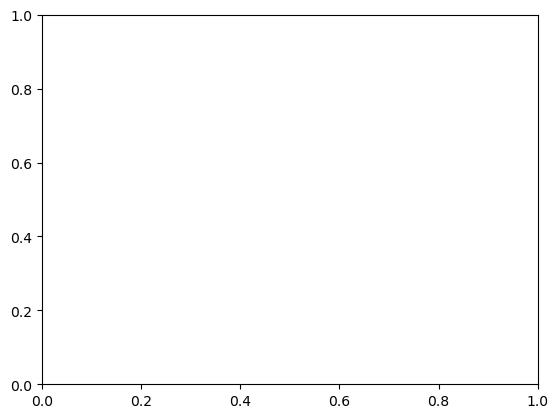

In [20]:
clicks = []
fig, ax = plt.subplots()
cid = fig.canvas.mpl_connect("button_press_event", lambda e: clicks.append((e.xdata, e.ydata)))
print("callback registered:", isinstance(cid, int))
fig.canvas.mpl_disconnect(cid)
print("interactive mode on:", plt.isinteractive())
plt.show()                                  # no-op under Agg
plt.close(fig)